In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import statsmodels.api as sm
import seaborn as sns

from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from scipy.stats import f
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    recall_score
)

from pathlib import Path


## target
探討不同先驗機率與錯誤分類成本，如何影響 LDA 的分類臨界值與分類結果。

## Data Reading

In [3]:
# Dataset path
BASE_DIR = Path.cwd()
file_path = BASE_DIR / "column_2C.dat"

# 2. Column names
columns = [
    "pelvic_incidence",
    "pelvic_tilt",
    "lumbar_lordosis_angle",
    "sacral_slope",
    "pelvic_radius",
    "degree_spondylolisthesis",
    "class"
]

# data reading
df = pd.read_csv(
    file_path,
    sep=r"\s+",     #以一個或多個空白字元分隔欄位
    header=None,    #沒有標題列
    names=columns   #手動指定七個欄位名稱
)

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nData Types:")
display(df.dtypes)


Dataset Shape: (310, 7)

First 5 Rows:


,pelvic_incidence,pelvic_tilt,lumbar_lordosis_angle,sacral_slope,pelvic_radius,degree_spondylolisthesis,class
0,63.03,22.55,39.61,40.48,98.67,-0.25,AB
1,39.06,10.06,25.02,29.00,114.41,4.56,AB
2,68.83,22.22,50.09,46.61,105.99,-3.53,AB
3,69.30,24.65,44.31,44.64,101.87,11.21,AB
4,49.71,9.65,28.32,40.06,108.17,7.92,AB



Data Types:


pelvic_incidence            float64
pelvic_tilt                 float64
lumbar_lordosis_angle       float64
sacral_slope                float64
pelvic_radius               float64
degree_spondylolisthesis    float64
class                           str
dtype: object

### Observation of data

In [4]:
#duplicate observations
duplicate_count = df.duplicated().sum()
print("Number of duplicated rows:", duplicate_count)
print("Duplicate percentage:", round(duplicate_count / len(df) * 100, 2), "%")

Number of duplicated rows: 0
Duplicate percentage: 0.0 %


In [5]:
# Missing values
print("\nMissing Values:")
print(df.isna().sum())


Missing Values:
pelvic_incidence            0
pelvic_tilt                 0
lumbar_lordosis_angle       0
sacral_slope                0
pelvic_radius               0
degree_spondylolisthesis    0
class                       0
dtype: int64


In [6]:
# Check variable ranges
print("\nVariable Ranges:")
display(pd.DataFrame({
    "Min": df.min(),
    "Max": df.max(),
    "Unique": df.nunique()
}))


Variable Ranges:


,Min,Max,Unique
pelvic_incidence,26.15,129.83,301
pelvic_tilt,-6.55,49.43,291
lumbar_lordosis_angle,14.0,125.74,271
sacral_slope,13.37,121.43,276
pelvic_radius,70.08,163.07,303
degree_spondylolisthesis,-11.06,418.54,305
class,AB,NO,2


##### Target distribution

In [7]:
# Target distribution
# 了解 Y = 0/1 的比例
print(df["class"].value_counts())

print("\nTarget percentage:")
print(
    df["class"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

class
AB    210
NO    100
Name: count, dtype: int64

Target percentage:
class
AB    67.74
NO    32.26
Name: proportion, dtype: float64


#### outlier detection

整體 Boxplot 顯示部分生物力學變數存在極端觀測值。我們進一步依診斷類別比較資料分布，觀察這些極端值是否集中於異常組，以及它們是否反映不同群體之間的分布差異，而非單純的資料錯誤。

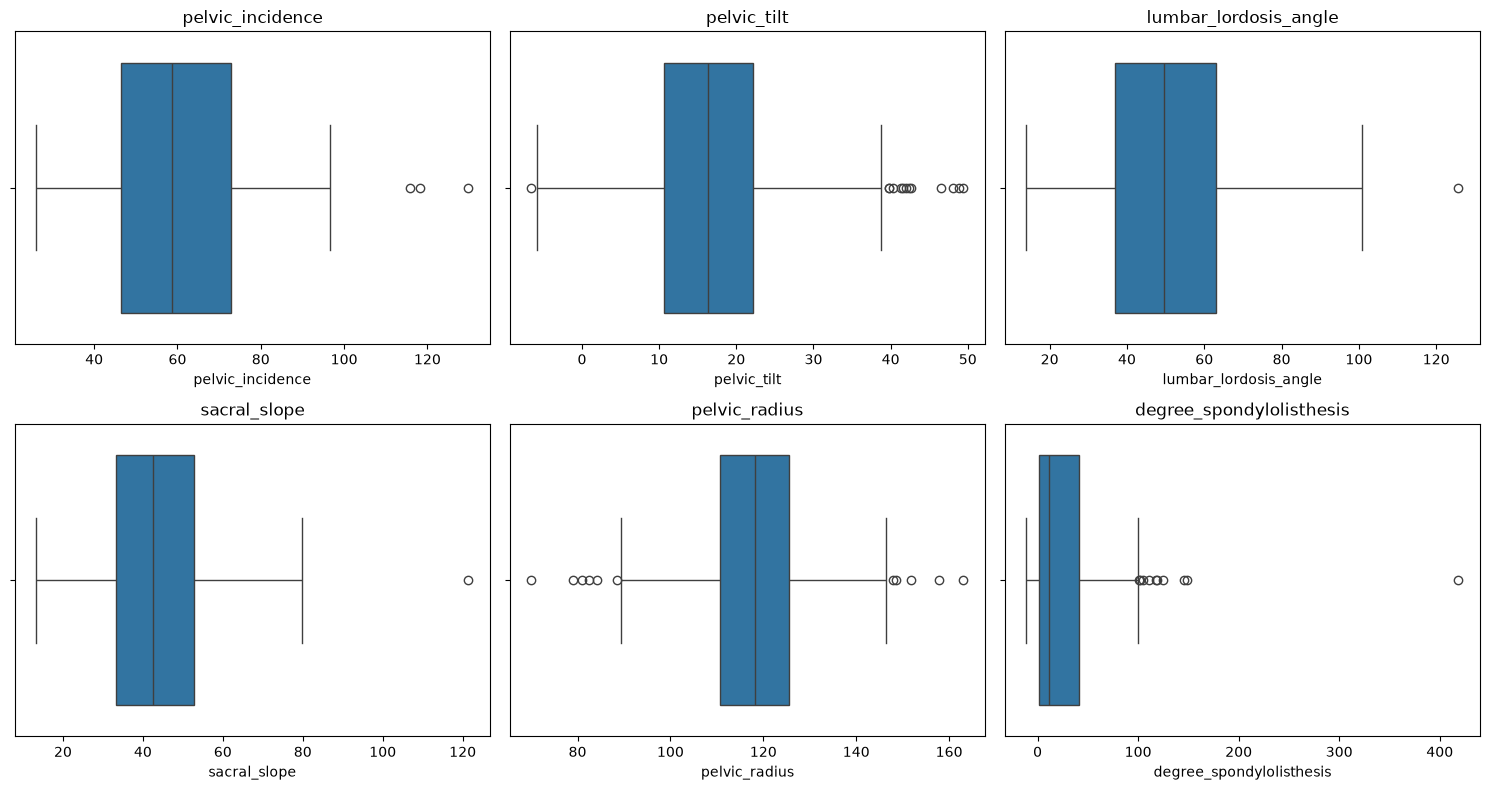

In [8]:
# 整體資料分布：IQR Method & boxplot

numeric_cols = df.select_dtypes(include="number").columns

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flatten(), numeric_cols):
    sns.boxplot(data=df, x=col, ax=ax)  # y=col 改成 x=col
    ax.set_title(col)

plt.tight_layout()
plt.show()

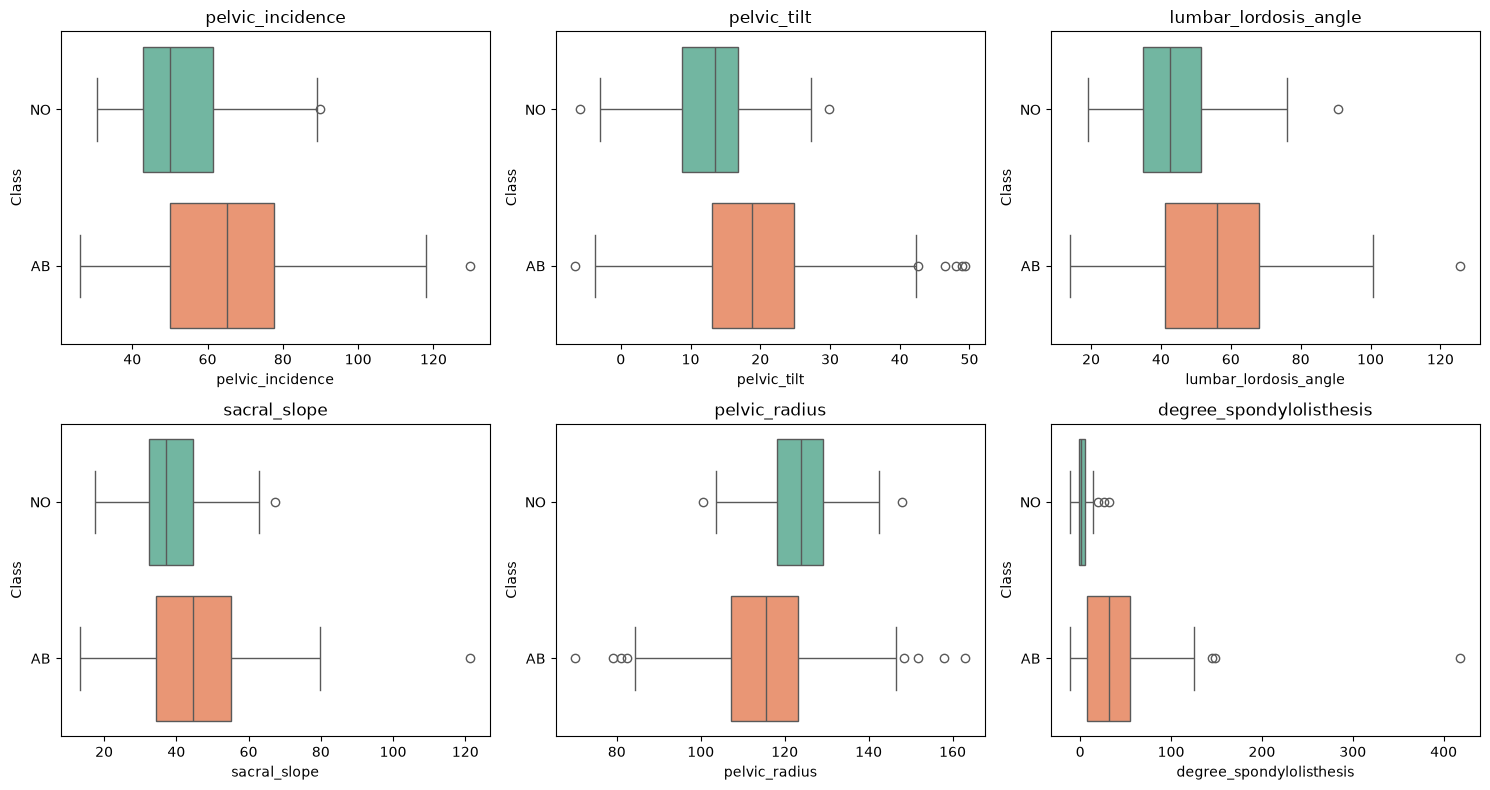

In [9]:
# Normal / Abnormal分組比較資料分布：IQR Method & boxplot

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flatten(), numeric_cols):
    sns.boxplot(
        data=df,
        x=col,
        y="class",
        hue="class",
        order=["NO", "AB"],
        hue_order=["NO", "AB"],
        palette="Set2",
        legend=False,
        ax=ax
    )
    ax.set_title(col)
    ax.set_ylabel("Class")

plt.tight_layout()
plt.show()


#### desciption statistics

In [10]:
# 五個變數整體資料的敘述統計量

numeric_cols = df.select_dtypes(include="number").columns

desc = df[numeric_cols].describe().T

desc["median"] = df[numeric_cols].median()
desc["IQR"] = desc["75%"] - desc["25%"]

display(desc.round(2))

# 分組後各自變數的平均數、中位數、標準差
group_stats = df.groupby("class")[numeric_cols].agg(
    ["mean", "median", "std"]
)

display(group_stats.round(2))

,count,mean,std,min,25%,50%,75%,max,median,IQR
pelvic_incidence,310.0,60.50,17.24,26.15,46.43,58.69,72.88,129.83,58.69,26.45
pelvic_tilt,310.0,17.54,10.01,-6.55,10.67,16.36,22.12,49.43,16.36,11.45
lumbar_lordosis_angle,310.0,51.93,18.55,14.00,37.00,49.56,63.00,125.74,49.56,26.00
sacral_slope,310.0,42.95,13.42,13.37,33.35,42.40,52.69,121.43,42.40,19.34
pelvic_radius,310.0,117.92,13.32,70.08,110.71,118.26,125.47,163.07,118.26,14.76
degree_spondylolisthesis,310.0,26.30,37.56,-11.06,1.60,11.76,41.28,418.54,11.76,39.68


pelvic_incidence               pelvic_tilt                \
                  mean median    std        mean median    std   
class                                                            
AB               64.69  65.28  17.66       19.79  18.80  10.52   
NO               51.69  50.12  12.37       12.82  13.48   6.78   

      lumbar_lordosis_angle               sacral_slope                \
                       mean median    std         mean median    std   
class                                                                  
AB                    55.93  56.15  19.67        44.90  44.64  14.52   
NO                    43.54  42.64  12.36        38.86  37.06   9.62   

      pelvic_radius                degree_spondylolisthesis                
               mean  median    std                     mean median    std  
class                                                                      
AB           115.08  115.65  14.09                    37.78  31.94  40.70  
NO           123.89  123.88   9.01                     2.19   1.16   6.31

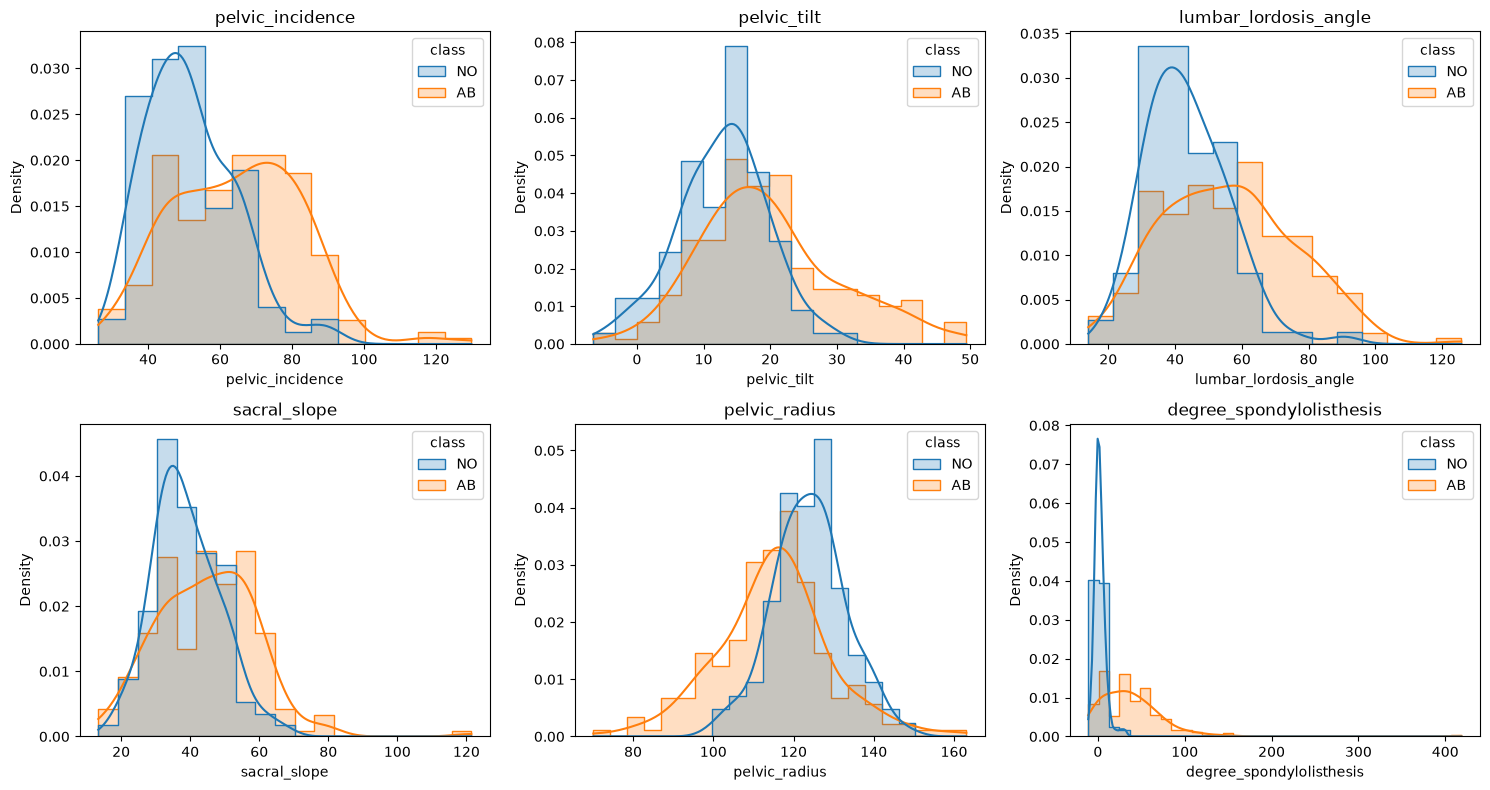

In [11]:
# 分組各自變數分布圖
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flatten(), numeric_cols):
    sns.histplot(
        data=df,
        x=col,
        hue="class",
        hue_order=["NO", "AB"],
        stat="density",
        common_norm=False,
        kde=True,
        element="step",
        alpha=0.25,
        ax=ax
    )
    ax.set_title(col)

plt.tight_layout()
plt.show()

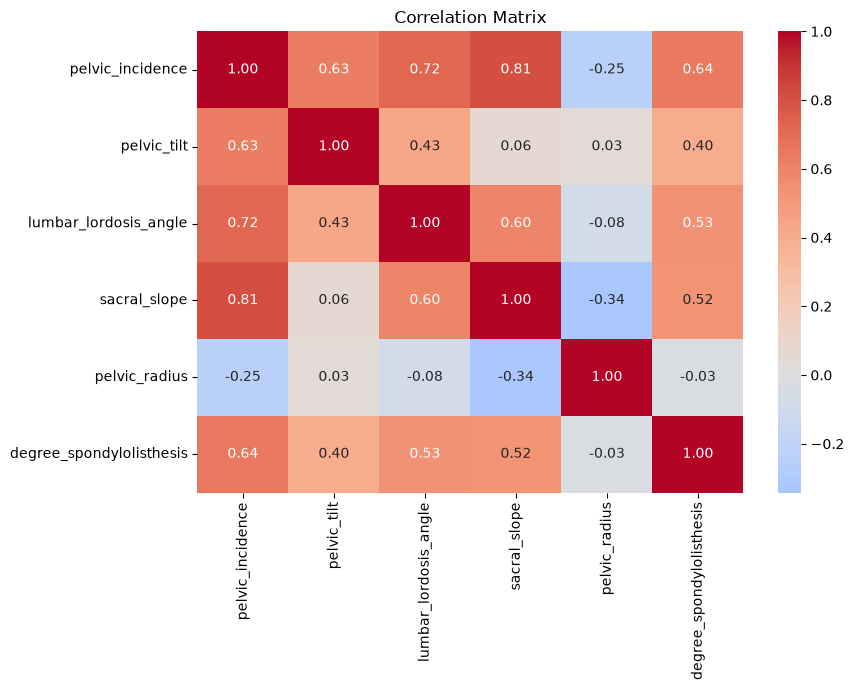

In [12]:
# 熱力圖
corr = df[numeric_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [13]:
# original VIF
features = [
    "pelvic_incidence",
    "pelvic_tilt",
    "lumbar_lordosis_angle",
    "sacral_slope",
    "pelvic_radius",
    "degree_spondylolisthesis"
]

# Add intercept for auxiliary regressions
X_vif = sm.add_constant(df[features].astype(float))

# Calculate VIF for each predictor
vif_results = pd.DataFrame({
    "Variable": features,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(1, X_vif.shape[1])
    ]
})

# Sort from highest to lowest
vif_results = vif_results.sort_values(
    by="VIF",
    ascending=False
)

display(vif_results.round(2))


,Variable,VIF
0,pelvic_incidence,10400551.10
3,sacral_slope,6308020.78
1,pelvic_tilt,3506684.72
2,lumbar_lordosis_angle,2.14
5,degree_spondylolisthesis,1.78
4,pelvic_radius,1.20


#### 變數定義分析
由於根據定義我們發現存在 PI = PT + SS 的關係，再加上觀察資料中PI, PT, SS 的最大絕對值差，可以驗證這個線性關係的結果，因此後續會在variable selection的時候決定選擇哪幾個變數建立模型。

In [14]:
difference = (
    df["pelvic_incidence"]
    - df["pelvic_tilt"]
    - df["sacral_slope"]
)

print("Maximum absolute difference:", difference.abs().max(), )

Maximum absolute difference: 0.010000000000005116


Degree of Spondylolisthesis名稱與脊椎滑脫診斷高度相關，因此需要確認：
- 它是否就是診斷分類的重要依據？
- 若保留它，模型是否可能過度依賴這項變數？
- 是否要把包含它的模型作為主要分析，並在研究限制中說明？

##### 目前決議
主要模型先保留 degree_spondylolisthesis。
理由是：
- 它是 UCI 官方提供的六個預測變數之一。
- 它目前具有六個變數中最高的單變量類別相關程度。
- 我們還沒有足夠證據證明它不應該用於建模。
- 我們的研究重點是不同 Prior 和 Error Cost 如何影響 Cut-off，而不是證明哪一種生物力學測量最好。
但為了確保它不會主導整個分類模型，未來可以額外建立一個不包含 degree_spondylolisthesis 的敏感度分析模型。

,Variable,Correlation_with_Y
4,pelvic_radius,-0.3099
3,sacral_slope,0.2106
2,lumbar_lordosis_angle,0.3125
1,pelvic_tilt,0.3260
0,pelvic_incidence,0.3533
5,degree_spondylolisthesis,0.4437


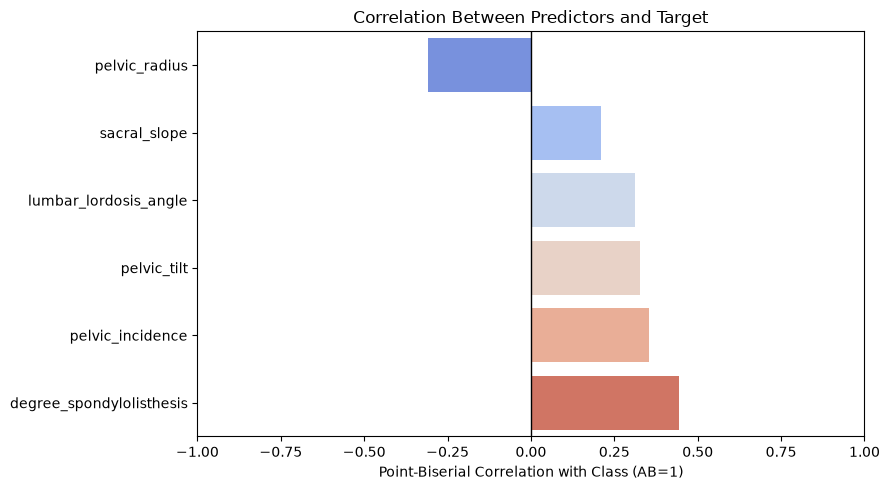

In [15]:
# Encode target variable (NO=0, AB=1)
y_encoded = df["class"].map({"NO": 0, "AB": 1})

# Calculate correlation of each X with Y
xy_corr = df[numeric_cols].corrwith(y_encoded)

# Create result table
xy_corr_df = (
    xy_corr
    .rename("Correlation_with_Y")
    .reset_index()
    .rename(columns={"index": "Variable"})
    .sort_values("Correlation_with_Y")
)

display(xy_corr_df.round(4))

# Plot
plt.figure(figsize=(9, 5))

sns.barplot(
    data=xy_corr_df,
    x="Correlation_with_Y",
    y="Variable",
    hue="Variable",
    palette="coolwarm",
    legend=False
)

plt.axvline(0, color="black", linewidth=1)
plt.xlim(-1, 1)
plt.xlabel("Point-Biserial Correlation with Class (AB=1)")
plt.ylabel("")
plt.title("Correlation Between Predictors and Target")

plt.tight_layout()
plt.show()


### 變異指標分析

#### 統計量數值計算
SST、SSTR、SSE、F-statistic、eta_sqr
通常當 F-statistic 越大、eta_sqr越高，就表示該變數的組間差異相對於組內分散程度越明顯。

In [16]:

numeric_cols = df.select_dtypes(include="number").columns

N = len(df)
K = df["class"].nunique()

results = []

for col in numeric_cols:

    # Overall mean
    overall_mean = df[col].mean()

    # Total Sum of Squares
    SST = ((df[col] - overall_mean) ** 2).sum()

    # Between-group Sum of Squares
    SSTR = 0

    # Within-group Sum of Squares
    SSE = 0

    for group_name, group in df.groupby("class"):

        n_k = len(group)
        group_mean = group[col].mean()

        SSTR += n_k * (group_mean - overall_mean) ** 2

        SSE += ((group[col] - group_mean) ** 2).sum()

    # Mean Squares
    MSTR = SSTR / (K - 1)
    MSE = SSE / (N - K)

    # F statistic
    F_stat = MSTR / MSE

    # Eta squared
    eta_squared = SSTR / SST

    results.append({
        "Variable": col,
        "SST": SST,
        "SSTR": SSTR,
        "SSE": SSE,
        "F-statistic": F_stat,
        "Eta Squared": eta_squared
    })

anova_summary = pd.DataFrame(results)

anova_summary = anova_summary.sort_values(
    by="Eta Squared",
    ascending=True
)

display(anova_summary.round(4))


,Variable,SST,SSTR,SSE,F-statistic,Eta Squared
3,sacral_slope,55672.5820,2469.4719,53203.1101,14.2961,0.0444
4,pelvic_radius,54804.0096,5262.4243,49541.5853,32.7165,0.0960
2,lumbar_lordosis_angle,106370.8478,10387.2758,95983.5720,33.3315,0.0977
1,pelvic_tilt,30950.3260,3290.2537,27660.0722,36.6376,0.1063
0,pelvic_incidence,91798.7873,11459.9139,80338.8734,43.9346,0.1248
5,degree_spondylolisthesis,435896.9360,85807.9492,350088.9868,75.4918,0.1969


## Modeling

### Full model

In [17]:
# add predictors
X = df.drop(columns=["class"])
y = df["class"]

# Full LDA Model
lda_full = LinearDiscriminantAnalysis(
    solver="svd",
    priors=[0.5, 0.5]       # 先設定base prior(0.5, 0.5)
)

lda_full.fit(X, y)

print("Model trained successfully!")
print("Classes:", lda_full.classes_)
print("Number of predictors:", X.shape[1])


Model trained successfully!
Classes: ['AB' 'NO']
Number of predictors: 6


In [18]:
# 觀察full model的判別函數

# Discriminant coefficients
coef_df = pd.DataFrame({
    "Variable": X.columns,
    "Coefficient": lda_full.coef_[0]
})

display(coef_df.round(4))

# Intercept
print("Intercept:", lda_full.intercept_[0])

# Group means
means_df = pd.DataFrame(
    lda_full.means_,
    columns=X.columns,
    index=lda_full.classes_
)

display(means_df.round(4))


,Variable,Coefficient
0,pelvic_incidence,10.7468
1,pelvic_tilt,-10.7857
2,lumbar_lordosis_angle,-0.0245
3,sacral_slope,-10.6901
4,pelvic_radius,0.0907
5,degree_spondylolisthesis,-0.0376


Intercept: -10.608286753518605


,pelvic_incidence,pelvic_tilt,lumbar_lordosis_angle,sacral_slope,pelvic_radius,degree_spondylolisthesis
AB,64.6921,19.7910,55.9252,44.9015,115.0774,37.7776
NO,51.6856,12.8218,43.5423,38.8638,123.8912,2.1870


### variable selection -- PI, PT, SS



```python
Model | 移除的變數 | 保留的幾何變數
Model A | Pelvic Incidence（PI）| PT、SS
Model B | Pelvic Tilt（PT）| PI、SS
Model C	| Sacral Slope（SS）| PI、PT
```

三個模型都使用全部 310 筆資料，且先驗機率統一設定為 Equal Prior（0.5、0.5），讓比較條件一致。
檢測accuracy, 判別分數相似程度, 各模型分類結果是否一致

In [19]:
# Target variable
y = df["class"]

# Three candidate models
model_features = {
    "Model A (Remove PI)": [
        "pelvic_tilt",
        "lumbar_lordosis_angle",
        "sacral_slope",
        "pelvic_radius",
        "degree_spondylolisthesis"
    ],
    "Model B (Remove PT)": [
        "pelvic_incidence",
        "lumbar_lordosis_angle",
        "sacral_slope",
        "pelvic_radius",
        "degree_spondylolisthesis"
    ],
    "Model C (Remove SS)": [
        "pelvic_incidence",
        "pelvic_tilt",
        "lumbar_lordosis_angle",
        "pelvic_radius",
        "degree_spondylolisthesis"
    ]
}

models = {}
results = []

for name, features in model_features.items():

    X_model = df[features]

    lda = LinearDiscriminantAnalysis(
        solver="svd",
        priors=[0.5, 0.5]
    )

    lda.fit(X_model, y)
    models[name] = lda

    # Training-set predictions
    y_pred = lda.predict(X_model)

    results.append({
        "Model": name,
        "Predictors": len(features),
        "Accuracy": (y_pred == y).mean()
    })

model_summary = pd.DataFrame(results)

display(model_summary.round(4))


,Model,Predictors,Accuracy
0,Model A (Remove PI),5,0.8065
1,Model B (Remove PT),5,0.8065
2,Model C (Remove SS),5,0.8065


In [20]:
score_df = pd.DataFrame(index=df.index)

for name, features in model_features.items():
    score_df[name] = models[name].decision_function(
        df[features]
    )

print("Correlation Between Model Scores:")
display(score_df.corr().round(4))

Correlation Between Model Scores:


,Model A (Remove PI),Model B (Remove PT),Model C (Remove SS)
Model A (Remove PI),1.0,1.0,1.0
Model B (Remove PT),1.0,1.0,1.0
Model C (Remove SS),1.0,1.0,1.0


In [21]:
pred_df = pd.DataFrame(index=df.index)

for name, features in model_features.items():
    pred_df[name] = models[name].predict(df[features])

# Check whether all three models give the same prediction
same_prediction = pred_df.nunique(axis=1) == 1

print("Number of identical predictions:",
      same_prediction.sum())

print("Number of different predictions:",
      (~same_prediction).sum())

print("Agreement Rate:",
      round(same_prediction.mean() * 100, 2), "%")

# Display observations with differing predictions
display(pred_df.loc[~same_prediction])

Number of identical predictions: 310
Number of different predictions: 0
Agreement Rate: 100.0 %


,Model A (Remove PI),Model B (Remove PT),Model C (Remove SS)


##### 原因
選擇Model C(remove SS)當作最終reduced model
原因：
三者在統計上沒有明顯優劣之分
就解釋性的角度來說，
PI 主要反映骨盆的解剖幾何形態，成年後通常相對穩定，不會隨一般姿勢改變而大幅變動。因此它能代表個體本身的骨盆結構特性。
PT 會隨骨盆的前傾、後傾而改變，可以反映身體透過調整骨盆姿態來維持脊椎矢狀面平衡的情況。因此 PT 具有姿態與代償機制上的解釋意義。
SS 描述薦骨上終板相對於水平面的角度，會隨骨盆姿態改變，並與腰椎前凸的幾何關係密切相關，與 PT 一樣，都屬於受姿態影響的參數。

In [22]:
# forward
# 1. Prepare data
features = [
    "pelvic_incidence",
    "pelvic_tilt",
    "lumbar_lordosis_angle",
    "sacral_slope",
    "pelvic_radius",
    "degree_spondylolisthesis"
]

X = df[features].astype(float)
y = df["class"].map({"NO": 0, "AB": 1}).to_numpy(dtype=float)

N = len(y)
K = 2

alpha_enter = 0.05
tolerance_limit = 1e-4


# 2. Calculate Wilks' Lambda
# For two groups, Lambda = 1 - R^2,
# where R^2 is obtained by regressing binary Y on X.
def wilks_lambda(cols):
    if not cols:
        return 1.0

    A = X[cols].to_numpy()
    A = A - A.mean(axis=0)

    y_centered = y - y.mean()

    beta = np.linalg.lstsq(A, y_centered, rcond=None)[0]
    residual = y_centered - A @ beta

    sse = np.sum(residual ** 2)
    sst = np.sum(y_centered ** 2)

    return sse / sst


# 3. Check redundancy of a candidate variable
def calculate_tolerance(candidate, selected):
    if not selected:
        return 1.0

    target = X[candidate].to_numpy()
    target = target - target.mean()

    A = X[selected].to_numpy()
    A = A - A.mean(axis=0)

    beta = np.linalg.lstsq(A, target, rcond=None)[0]
    residual = target - A @ beta

    return np.sum(residual**2) / np.sum(target**2)


# Forward Selection
selected = []
remaining = features.copy()
history = []

current_lambda = 1.0

while remaining:
    candidates = []

    for variable in remaining:

        tolerance = calculate_tolerance(variable, selected)

        # Skip nearly redundant predictors
        if tolerance < tolerance_limit:
            continue

        new_lambda = wilks_lambda(selected + [variable])

        partial_lambda = new_lambda / current_lambda

        df1 = K - 1
        df2 = N - K - len(selected)

        F_stat = (
            ((1 - partial_lambda) / partial_lambda)
            * (df2 / df1)
        )

        p_value = f.sf(F_stat, df1, df2)

        candidates.append({
            "Variable": variable,
            "Wilks Lambda": new_lambda,
            "Partial Lambda": partial_lambda,
            "F-to-enter": F_stat,
            "p-value": p_value,
            "Tolerance": tolerance
        })

    if not candidates:
        break

    # Choose the candidate with the largest F
    best = max(candidates, key=lambda x: x["F-to-enter"])

    # Stop if no candidate passes entry criterion
    if best["p-value"] >= alpha_enter:
        break

    selected.append(best["Variable"])
    remaining.remove(best["Variable"])

    current_lambda = best["Wilks Lambda"]

    history.append({
        "Step": len(selected),
        **best
    })


# 5. Results
forward_results = pd.DataFrame(history)

print("Selected Variables:")
print(selected)

print("\nExcluded Variables:")
print([v for v in features if v not in selected])

print("\nforward Selection History:")
display(forward_results.round(6))


Selected Variables:
['degree_spondylolisthesis', 'pelvic_radius', 'pelvic_tilt', 'pelvic_incidence', 'lumbar_lordosis_angle']

Excluded Variables:
['sacral_slope']

forward Selection History:


,Step,Variable,Wilks Lambda,Partial Lambda,F-to-enter,p-value,Tolerance
0,1,degree_spondylolisthesis,0.803146,0.803146,75.491802,0.000000,1.000000
1,2,pelvic_radius,0.714099,0.889127,38.282657,0.000000,0.999320
2,3,pelvic_tilt,0.682704,0.956036,14.071515,0.000210,0.839870
3,4,pelvic_incidence,0.667824,0.978204,6.795817,0.009586,0.362205
4,5,lumbar_lordosis_angle,0.658732,0.986385,4.196185,0.041374,0.466639


In [23]:
# backward
# 1. All six candidate variables
features = [
    "pelvic_incidence",
    "pelvic_tilt",
    "lumbar_lordosis_angle",
    "sacral_slope",
    "pelvic_radius",
    "degree_spondylolisthesis"
]

X = df[features].astype(float)
y = df["class"].map({"NO": 0, "AB": 1}).to_numpy(float)

N = len(y)
K = 2
alpha_remove = 0.05


# 2. Wilks' Lambda for two-group DA
def wilks_lambda(cols):
    if len(cols) == 0:
        return 1.0

    A = X[cols].to_numpy()
    A = A - A.mean(axis=0)

    yc = y - y.mean()

    beta = np.linalg.lstsq(A, yc, rcond=None)[0]
    residual = yc - A @ beta

    return np.sum(residual**2) / np.sum(yc**2)


# 3. Backward Elimination
selected_backward = features.copy()
backward_history = []
backward_candidates = []

step = 0

while len(selected_backward) > 0:

    p = len(selected_backward)
    lambda_full = wilks_lambda(selected_backward)

    candidates = []

    for variable in selected_backward:

        reduced = [
            v for v in selected_backward
            if v != variable
        ]

        lambda_reduced = wilks_lambda(reduced)

        # Partial Wilks' Lambda:
        # Full model / Reduced model
        partial_lambda = lambda_full / lambda_reduced

        # Partial F test for removing one variable
        df1 = 1
        df2 = N - p - 1

        F_remove = (
            (lambda_reduced / lambda_full - 1)
            * df2
        )

        F_remove = max(0.0, F_remove)
        p_value = f.sf(F_remove, df1, df2)

        candidates.append({
            "Variable": variable,
            "Partial Lambda": partial_lambda,
            "F-to-remove": F_remove,
            "p-value": p_value,
            "Lambda after removal": lambda_reduced
        })

    # Save candidate tests at each step
    candidate_df = pd.DataFrame(candidates)
    candidate_df["Step"] = step + 1
    backward_candidates.append(candidate_df)

    # Remove variable with largest p-value
    worst = max(candidates, key=lambda x: x["p-value"])

    # Stop when all remaining variables are significant
    if worst["p-value"] <= alpha_remove:
        break

    selected_backward.remove(worst["Variable"])
    step += 1

    backward_history.append({
        "Step": step,
        "Removed Variable": worst["Variable"],
        "F-to-remove": worst["F-to-remove"],
        "p-value": worst["p-value"],
        "Wilks Lambda": worst["Lambda after removal"],
        "Remaining Variables": len(selected_backward)
    })


# 4. Display results
backward_results = pd.DataFrame(backward_history)

print("Final Selected Variables:")
print(selected_backward)

print("\nRemoved Variables:")
print([v for v in features if v not in selected_backward])

print("\nBackward Elimination History:")
display(backward_results.round(6))

print("\nFirst-step Candidate Tests:")
display(backward_candidates[0].round(6))


Final Selected Variables:
['pelvic_incidence', 'pelvic_tilt', 'lumbar_lordosis_angle', 'pelvic_radius', 'degree_spondylolisthesis']

Removed Variables:
['sacral_slope']

Backward Elimination History:


,Step,Removed Variable,F-to-remove,p-value,Wilks Lambda,Remaining Variables
0,1,sacral_slope,0.141838,0.706725,0.658732,5



First-step Candidate Tests:


,Variable,Partial Lambda,F-to-remove,p-value,Lambda after removal,Step
0,pelvic_incidence,0.999527,0.143357,0.705232,0.658735,1
1,pelvic_tilt,0.999524,0.144393,0.704218,0.658737,1
2,lumbar_lordosis_angle,0.986414,4.173321,0.041930,0.667492,1
3,sacral_slope,0.999532,0.141838,0.706725,0.658732,1
4,pelvic_radius,0.851422,52.875132,0.000000,0.773322,1
5,degree_spondylolisthesis,0.861476,48.721993,0.000000,0.764297,1


In [24]:
# comparing
forward_set = set(selected)
backward_set = set(selected_backward)

comparison = pd.DataFrame({
    "Variable": features,
    "Forward": [
        "Selected" if v in forward_set else "Excluded"
        for v in features
    ],
    "Backward": [
        "Selected" if v in backward_set else "Excluded"
        for v in features
    ]
})

display(comparison)

,Variable,Forward,Backward
0,pelvic_incidence,Selected,Selected
1,pelvic_tilt,Selected,Selected
2,lumbar_lordosis_angle,Selected,Selected
3,sacral_slope,Excluded,Excluded
4,pelvic_radius,Selected,Selected
5,degree_spondylolisthesis,Selected,Selected


### Reduced Model

處理完共線變數，同時發現其他三個變數也會被選進模型，因此最終模型變數只刪掉一個。

In [25]:
# Reduced Model

if not selected:
    print("No variables met the entry criterion.")
else:
    X_reduced = df[selected]

    lda_reduced = LinearDiscriminantAnalysis(
        solver="svd",
        priors=[0.5, 0.5]
    )

    lda_reduced.fit(X_reduced, df["class"])

    print("Reduced LDA trained successfully!")
    print("Selected predictors:", selected)
    print("Classes:", lda_reduced.classes_)

    coef_df = pd.DataFrame({
        "Variable": selected,
        "Coefficient": lda_reduced.coef_[0]
    })

    display(coef_df.round(4))
    print("Intercept:", lda_reduced.intercept_[0])


Reduced LDA trained successfully!
Selected predictors: ['degree_spondylolisthesis', 'pelvic_radius', 'pelvic_tilt', 'pelvic_incidence', 'lumbar_lordosis_angle']
Classes: ['AB' 'NO']


,Variable,Coefficient
0,degree_spondylolisthesis,-0.0377
1,pelvic_radius,0.0908
2,pelvic_tilt,-0.0958
3,pelvic_incidence,0.0571
4,lumbar_lordosis_angle,-0.0245


Intercept: -10.636888420371537


In [26]:
# 檢查刪除完變數的共線性

# Five predictors after removing sacral_slope
reduced_features = [
    col for col in features
    if col != "sacral_slope"
]

X_reduced_vif = sm.add_constant(
    df[reduced_features].astype(float)
)

vif_reduced = pd.DataFrame({
    "Variable": reduced_features,
    "VIF_After": [
        variance_inflation_factor(
            X_reduced_vif.values, i
        )
        for i in range(1, X_reduced_vif.shape[1])
    ]
})

# Merge before and after
vif_comparison = vif_results.rename(
    columns={"VIF": "VIF_Before"}
).merge(
    vif_reduced,
    on="Variable",
    how="left"
)

display(vif_comparison.round(2))


,Variable,VIF_Before,VIF_After
0,pelvic_incidence,10400551.10,3.85
1,sacral_slope,6308020.78,NaN
2,pelvic_tilt,3506684.72,1.78
3,lumbar_lordosis_angle,2.14,2.14
4,degree_spondylolisthesis,1.78,1.77
5,pelvic_radius,1.20,1.20


## Model Analysis

目前模型：
\[
\begin{aligned}
D(X)={}&-10.6369\\
&-0.0377X_{\text{DS}}\\
&+0.0908X_{\text{PR}}\\
&-0.0958X_{\text{PT}}\\
&+0.0571X_{\text{PI}}\\
&-0.0245X_{\text{LLA}}
\end{aligned}
\]

### Final Model

In [27]:
# 轉換成fisher discriminant function 以調整cutoff value

# Use the final selected model
X_final = df[selected]
y = df["class"]

lda_final = lda_reduced
print("Classes:", lda_final.classes_)

# Ensure the predictor order matches the trained model
final_features = list(lda_final.feature_names_in_)

# Fisher coefficients
k = lda_final.coef_[0]

coef_df = pd.DataFrame({
    "Variable": final_features,
    "Coefficient": k
})

display(coef_df.round(4))

# Fisher Projection Score (without intercept)
t = X_final.to_numpy() @ k

score_df = pd.DataFrame({
    "Class": y.to_numpy(),
    "Fisher_Score": t
}, index=df.index)

# Group mean Fisher scores
t_bar = score_df.groupby("Class")["Fisher_Score"].mean()

t_bar_NO = t_bar["NO"]
t_bar_AB = t_bar["AB"]

# Base cut-off: teacher's midpoint method
t_bar_bar = (t_bar_NO + t_bar_AB) / 2

print(f"Mean Fisher Score (NO): {t_bar_NO:.4f}")
print(f"Mean Fisher Score (AB): {t_bar_AB:.4f}")
print(f"Base Cut-off (t_bar_bar): {t_bar_bar:.4f}")

# Classification direction:
# t > t_bar_bar -> NO
# t <= t_bar_bar -> AB


Classes: ['AB' 'NO']


,Variable,Coefficient
0,degree_spondylolisthesis,-0.0377
1,pelvic_radius,0.0908
2,pelvic_tilt,-0.0958
3,pelvic_incidence,0.0571
4,lumbar_lordosis_angle,-0.0245


Mean Fisher Score (NO): 11.8223
Mean Fisher Score (AB): 9.4515
Base Cut-off (t_bar_bar): 10.6369


數學變化：
原本：
\[
D(X)=b_0+\mathbf{k}^T\mathbf{x}
\]

現在：
\[
\boxed{t(X)=\mathbf{k}^T\mathbf{x}}
\]

,count,mean,std,median,min,max
Class,,,,,,
AB,210,9.4515,1.7511,9.7380,-0.5813,14.5831
NO,100,11.8223,0.9747,11.8095,9.4233,14.3994


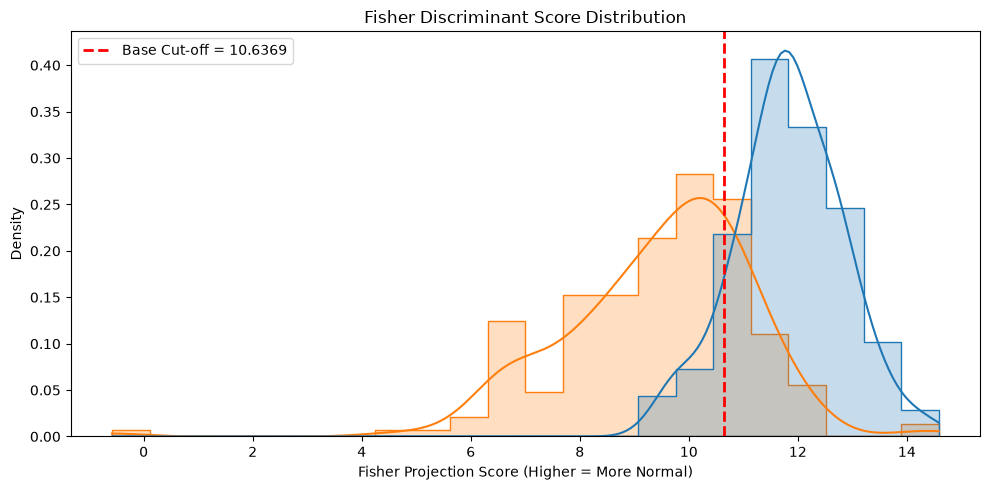

In [28]:
# Fisher Score Distribution

# Descriptive statistics by class
display(
    score_df.groupby("Class")["Fisher_Score"]
    .agg(["count", "mean", "std", "median", "min", "max"])
    .round(4)
)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=score_df,
    x="Fisher_Score",
    hue="Class",
    hue_order=["NO", "AB"],
    stat="density",
    common_norm=False,
    kde=True,
    element="step",
    alpha=0.25
)

# Teacher's Base Cut-off
plt.axvline(
    t_bar_bar,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Base Cut-off = {t_bar_bar:.4f}"
)

plt.title("Fisher Discriminant Score Distribution")
plt.xlabel("Fisher Projection Score (Higher = More Normal)")
plt.ylabel("Density")
plt.legend()

plt.tight_layout()
plt.show()


#### confusion matrix

In [29]:
from sklearn.metrics import confusion_matrix, accuracy_score

# Classification using Fisher Base Cut-off
y_pred_base = np.where(t > t_bar_bar, "NO", "AB")

# Confusion Matrix
# let AB(abnormal) be positive class
cm_base = confusion_matrix(
    y,
    y_pred_base,
    labels=["AB", "NO"]
)

cm_df = pd.DataFrame(
    cm_base,
    index=["Actual AB", "Actual NO"],
    columns=["Predicted AB", "Predicted NO"]
)

display(cm_df)

# In-sample Accuracy
accuracy_base = accuracy_score(y, y_pred_base)

print(f"Base Cut-off: {t_bar_bar:.4f}")
print(f"In-sample Accuracy: {accuracy_base:.2%}")


,Predicted AB,Predicted NO
Actual AB,160,50
Actual NO,10,90


Base Cut-off: 10.6369
In-sample Accuracy: 80.65%


In [30]:
# Scenario 1: Sample Prior Cut-off
cutoff_base = t_bar_bar


n_NO = (y == "NO").sum()
n_AB = (y == "AB").sum()

prior_NO = n_NO / (n_NO + n_AB) #100/310
prior_AB = n_AB / (n_NO + n_AB) #210/310

# Within-group sample variances
var_NO = score_df.loc[
    score_df["Class"] == "NO", "Fisher_Score"
].var()

var_AB = score_df.loc[
    score_df["Class"] == "AB", "Fisher_Score"
].var()

# Pooled within-group variance
pooled_var = (
    (n_NO - 1) * var_NO
    + (n_AB - 1) * var_AB
) / (n_NO + n_AB - 2)

# Adjustment scale for Fisher projection
scale = pooled_var / (t_bar_NO - t_bar_AB)

cutoff_prior = (
    cutoff_base
    + scale * np.log(prior_AB / prior_NO)
)

print("Scenario 1: Sample Prior Cut-off")
print(f"Prior NO = {prior_NO:.4f}")
print(f"Prior AB = {prior_AB:.4f}")
print(f"Pooled Variance = {pooled_var:.4f}")
print(f"Scale = {scale:.4f}")
print(f"Cut-off = {cutoff_prior:.4f}")


Scenario 1: Sample Prior Cut-off
Prior NO = 0.3226
Prior AB = 0.6774
Pooled Variance = 2.3862
Scale = 1.0065
Cut-off = 11.3836


In [31]:
# Scenario 2: Cost-sensitive Cut-off
# 假設沒有抓出異常的成本較高

cost_FP = 1
cost_FN = 5

cutoff_cost = (
    cutoff_base
    + scale * np.log(cost_FN / cost_FP)
)

print("Scenario D: Cost-sensitive Cut-off")
print(f"FP Cost = {cost_FP}")
print(f"FN Cost = {cost_FN}")
print(f"Cut-off = {cutoff_cost:.4f}")


Scenario D: Cost-sensitive Cut-off
FP Cost = 1
FN Cost = 5
Cut-off = 12.2568


In [40]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score
)

cutoffs = {
    "Base (Mean Midpoint)": cutoff_base,
    "Sample Prior": cutoff_prior,
    "Cost-sensitive (5:1)": cutoff_cost
}


results = []

for name, cutoff in cutoffs.items():

    # Fisher classification rule
    y_pred = np.where(t > cutoff, "NO", "AB")

    # AB is the Positive Class
    cm = confusion_matrix(
        y,
        y_pred,
        labels=["AB", "NO"]
    )

    TP, FN = cm[0]
    FP, TN = cm[1]

    results.append({
        "Scenario": name,
        "Cut-off": cutoff,
        "TP": TP,
        "TN": TN,
        "FP": FP,
        "FN": FN,
        "Accuracy": accuracy_score(y, y_pred),
        "Recall AB": TP / (TP + FN),
        "Recall NO": TN / (TN + FP),
        "Balanced Accuracy": balanced_accuracy_score(y, y_pred)
    })

comparison_df = pd.DataFrame(results)

display(comparison_df.round(4))


,Scenario,Cut-off,TP,TN,FP,FN,Accuracy,Recall AB,Recall NO,Balanced Accuracy
0,Base (Mean Midpoint),10.6369,160,90,10,50,0.8065,0.7619,0.90,0.8310
1,Sample Prior,11.3836,193,73,27,17,0.8581,0.9190,0.73,0.8245
2,Cost-sensitive (5:1),12.2568,207,32,68,3,0.7710,0.9857,0.32,0.6529


In [33]:
# Cost Ratio Sensitivity Analysis
# Equal Prior: P(NO) = P(AB) = 0.5

cost_ratios = [1, 2, 3, 5, 10]
cost_results = []

for r in cost_ratios:

    cutoff = cutoff_base + scale * np.log(r)

    # Higher Fisher score means NO
    y_pred = np.where(t > cutoff, "NO", "AB")

    cm = confusion_matrix(
        y, y_pred, labels=["AB", "NO"]
    )

    TP, FN = cm[0]
    FP, TN = cm[1]

    cost_results.append({
        "FN/FP Cost Ratio": r,
        "Cut-off": cutoff,
        "TP": TP,
        "FN": FN,
        "FP": FP,
        "TN": TN,
        "Accuracy": (TP + TN) / len(y),
        "Recall AB": TP / (TP + FN),
        "Recall NO": TN / (TN + FP)
    })

cost_sensitivity_df = pd.DataFrame(cost_results)

display(cost_sensitivity_df.round(4))


,FN/FP Cost Ratio,Cut-off,TP,FN,FP,TN,Accuracy,Recall AB,Recall NO
0,1,10.6369,160,50,10,90,0.8065,0.7619,0.90
1,2,11.3345,189,21,26,74,0.8484,0.9000,0.74
2,3,11.7426,200,10,46,54,0.8194,0.9524,0.54
3,5,12.2568,207,3,68,32,0.7710,0.9857,0.32
4,10,12.9544,208,2,88,12,0.7097,0.9905,0.12


In [34]:
# Constrained Sensitivity Analysis
# Goal: Maximize NO Recall subject to AB Recall >= 90%

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

target_sensitivity = 0.90

# AB is the positive class
actual_AB = (y.to_numpy() == "AB")
actual_NO = (y.to_numpy() == "NO")

# Test all observed Fisher scores as candidate cut-offs
candidate_cutoffs = np.sort(np.unique(t))

results = []

for cutoff in candidate_cutoffs:

    # Fisher classification rule:
    # t <= cutoff -> AB
    # t > cutoff  -> NO
    predicted_AB = (t <= cutoff)

    TP = np.sum(actual_AB & predicted_AB)
    FN = np.sum(actual_AB & ~predicted_AB)
    FP = np.sum(actual_NO & predicted_AB)
    TN = np.sum(actual_NO & ~predicted_AB)

    sensitivity = TP / (TP + FN)
    specificity = TN / (TN + FP)

    results.append({
        "Cut-off": cutoff,
        "TP": TP,
        "FN": FN,
        "FP": FP,
        "TN": TN,
        "Sensitivity": sensitivity,
        "Specificity": specificity
    })

constraint_df = pd.DataFrame(results)

# Keep only cut-offs satisfying minimum sensitivity
feasible_df = constraint_df[
    constraint_df["Sensitivity"] >= target_sensitivity
]

# Highest specificity; use smallest cut-off to break ties
optimal_row = feasible_df.sort_values(
    ["Specificity", "Cut-off"],
    ascending=[False, True]
).iloc[0]

cutoff_constrained = optimal_row["Cut-off"]

print(f"Target Sensitivity: {target_sensitivity:.0%}")
print(f"Optimal Cut-off: {cutoff_constrained:.4f}")
print(f"AB Recall: {optimal_row['Sensitivity']:.2%}")
print(f"NO Recall: {optimal_row['Specificity']:.2%}")
print(f"False Negatives: {int(optimal_row['FN'])}")
print(f"False Positives: {int(optimal_row['FP'])}")

display(pd.DataFrame([optimal_row]).round(4))


Target Sensitivity: 90%
Optimal Cut-off: 11.2911
AB Recall: 90.00%
NO Recall: 75.00%
False Negatives: 21
False Positives: 25


,Cut-off,TP,FN,FP,TN,Sensitivity,Specificity
213,11.2911,189.0,21.0,25.0,75.0,0.9,0.75


##### cut-off value _修正

In [35]:
import numpy as np
import pandas as pd
from scipy.stats import gaussian_kde

# Group Fisher scores
scores_AB = score_df.loc[
    score_df["Class"] == "AB", "Fisher_Score"
].to_numpy()

scores_NO = score_df.loc[
    score_df["Class"] == "NO", "Fisher_Score"
].to_numpy()

# 1. Mean midpoint (existing Base Cut-off)
cutoff_mean = (scores_AB.mean() + scores_NO.mean()) / 2

# 2. Median midpoint
median_AB = np.median(scores_AB)
median_NO = np.median(scores_NO)

cutoff_median = (median_AB + median_NO) / 2

# 3. KDE-estimated mode
def estimate_mode(scores):
    kde = gaussian_kde(scores)
    grid = np.linspace(scores.min(), scores.max(), 5000)
    return grid[np.argmax(kde(grid))]

mode_AB = estimate_mode(scores_AB)
mode_NO = estimate_mode(scores_NO)

cutoff_mode = (mode_AB + mode_NO) / 2

# Compare group centers and cut-offs
center_df = pd.DataFrame({
    "AB": [scores_AB.mean(), median_AB, mode_AB],
    "NO": [scores_NO.mean(), median_NO, mode_NO],
    "Midpoint Cut-off": [
        cutoff_mean,
        cutoff_median,
        cutoff_mode
    ]
}, index=["Mean", "Median", "Mode (KDE)"])

display(center_df.round(4))


,AB,NO,Midpoint Cut-off
Mean,9.4515,11.8223,10.6369
Median,9.7380,11.8095,10.7737
Mode (KDE),10.2058,11.7755,10.9906


In [36]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score
)

center_cutoffs = {
    "Mean Midpoint (Base)": cutoff_mean,
    "Median Midpoint": cutoff_median,
    "Mode Midpoint (KDE)": cutoff_mode
}

center_results = []

for name, cutoff in center_cutoffs.items():

    y_pred = np.where(t > cutoff, "NO", "AB")

    cm = confusion_matrix(
        y, y_pred, labels=["AB", "NO"]
    )

    TP, FN = cm[0]
    FP, TN = cm[1]

    center_results.append({
        "Method": name,
        "Cut-off": cutoff,
        "TP": TP,
        "TN": TN,
        "FP": FP,
        "FN": FN,
        "Accuracy": accuracy_score(y, y_pred),
        "Recall AB": TP / (TP + FN),
        "Recall NO": TN / (TN + FP),
        "Balanced Accuracy": balanced_accuracy_score(y, y_pred)
    })

center_comparison_df = pd.DataFrame(center_results)

display(center_comparison_df.round(4))


,Method,Cut-off,TP,TN,FP,FN,Accuracy,Recall AB,Recall NO,Balanced Accuracy
0,Mean Midpoint (Base),10.6369,160,90,10,50,0.8065,0.7619,0.90,0.8310
1,Median Midpoint,10.7737,168,89,11,42,0.8290,0.8000,0.89,0.8450
2,Mode Midpoint (KDE),10.9906,178,82,18,32,0.8387,0.8476,0.82,0.8338


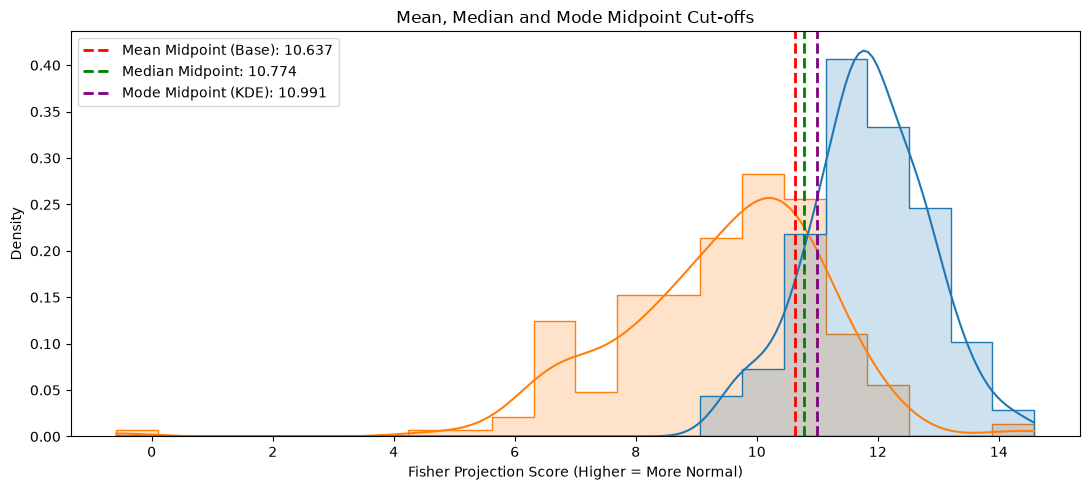

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 5))

sns.histplot(
    data=score_df,
    x="Fisher_Score",
    hue="Class",
    hue_order=["NO", "AB"],
    stat="density",
    common_norm=False,
    kde=True,
    element="step",
    alpha=0.22
)

colors = {
    "Mean Midpoint (Base)": "red",
    "Median Midpoint": "green",
    "Mode Midpoint (KDE)": "purple"
}

for name, cutoff in center_cutoffs.items():
    plt.axvline(
        cutoff,
        color=colors[name],
        linestyle="--",
        linewidth=2,
        label=f"{name}: {cutoff:.3f}"
    )

plt.title("Mean, Median and Mode Midpoint Cut-offs")
plt.xlabel("Fisher Projection Score (Higher = More Normal)")
plt.ylabel("Density")
plt.legend()

plt.tight_layout()
plt.show()
